# VGGT — reconstruct the `~/test_piv` multi-view set

Runs the **vggt** box (Meta VGGT multi-view 3D reconstruction) against the
8 frames in `~/test_piv` and returns world-space points, per-view depth,
camera intrinsics/extrinsics.

## Prerequisite
The service is running. Here it is the `visionist-vggt` container publishing
`localhost:9066 -> 8061`. Change `TARGET` in the Parameters cell if yours
differs (e.g. `localhost:8061` for a direct docker run).

> All 8 input frames are 6204x4132 (identical) — required by the box contract.
> The model internally downsamples to ~518px wide, so outputs are at that
> reduced resolution (350x518 for these frames).


## 0. Locate the shared gRPC protos


In [1]:
import os, sys

# Robustly locate the box's shared `protos/` dir (pipeline_pb2 / aux),
# regardless of what the kernel CWD is.
here = os.path.abspath(os.getcwd())
candidates = [
    os.path.join(here, "protos"),                              # CWD == box root
    os.path.join(here, "..", "protos"),                        # CWD == box/test
    "/home/manuelf/VisionIST_Library/boxes/vggt/protos",       # absolute fallback
]
protos_dir = next((os.path.abspath(c) for c in candidates
                   if os.path.isfile(os.path.join(c, "pipeline_pb2.py"))), None)
assert protos_dir, "could not locate the box 'protos' directory (pipeline_pb2.py)"
if protos_dir not in sys.path:
    sys.path.insert(0, protos_dir)
print("using protos from:", protos_dir)


using protos from: /home/manuelf/VisionIST_Library/boxes/vggt/protos


## 1. Parameters


In [6]:
import json, io, time, glob
import numpy as np
import torch
import matplotlib.pyplot as plt

import grpc
import pipeline_pb2
import pipeline_pb2_grpc
from aux import wrap_value, unwrap_value

TARGET      = "localhost:9066"   # running vggt container (host 9066 -> 8061)
IMG_DIR     = os.path.expanduser("~/test_piv/praca_1")
CONF_THRESH = 30                  # GLB confidence/percentile filter (higher = sparser)
DEVICE      = None                # None => box auto-picks (GPU when available); or "cuda" / "cpu"
OUT_DIR     = os.path.abspath(os.path.join(protos_dir, "..", "test", "test_piv_out"))

for k in ("TARGET", "IMG_DIR", "CONF_THRESH", "DEVICE", "OUT_DIR"):
    print(f"{k:<12} =", eval(k))


TARGET       = localhost:9066
IMG_DIR      = /home/manuelf/test_piv/praca_1
CONF_THRESH  = 30
DEVICE       = None
OUT_DIR      = /home/manuelf/VisionIST_Library/boxes/vggt/test/test_piv_out


## 2. Load the `~/test_piv` frames and build the request


In [3]:
from PIL import Image

_cands  = (sorted(glob.glob(os.path.join(IMG_DIR, "*.jpg"))) +
           sorted(glob.glob(os.path.join(IMG_DIR, "*.png"))))
paths   = [p for p in dict.fromkeys(_cands) if os.path.isfile(p)]
assert len(paths) >= 2, f"need at least 2 views, found {len(paths)} in {IMG_DIR}"
print(f"{len(paths)} frames from {IMG_DIR}")
for p in paths:
    with Image.open(p) as im:
        print(f"  {os.path.basename(p):>14}   {im.size[0]}x{im.size[1]}  {im.mode}")

# identical dimensions are a hard requirement of the box contract
shapes = {Image.open(p).size for p in paths}
print("distinct (w,h):", shapes, "->", "OK" if len(shapes) == 1 else "MISMATCH (will error on the server)")

image_byte_list = [open(p, "rb").read() for p in paths]
print(f"upload payload: {sum(map(len, image_byte_list)) / (1024*1024):.1f} MB total")

config = {"vggt": {"command": "reconstruct", "parameters": {"conf_threshold": CONF_THRESH}}}
if DEVICE:
    config["vggt"]["parameters"]["device"] = DEVICE
print("config_json:", json.dumps(config))

request = pipeline_pb2.Envelope(
    data={"images": wrap_value(image_byte_list)},
    config_json=json.dumps(config),
)


16 frames from /home/manuelf/test_piv/praca_1
   crop_yaw0.png   1920x1080  RGB
   crop_yaw1.png   1920x1080  RGB
  crop_yaw10.png   1920x1080  RGB
  crop_yaw11.png   1920x1080  RGB
  crop_yaw12.png   1920x1080  RGB
  crop_yaw13.png   1920x1080  RGB
  crop_yaw14.png   1920x1080  RGB
  crop_yaw15.png   1920x1080  RGB
   crop_yaw2.png   1920x1080  RGB
   crop_yaw3.png   1920x1080  RGB
   crop_yaw4.png   1920x1080  RGB
   crop_yaw5.png   1920x1080  RGB
   crop_yaw6.png   1920x1080  RGB
   crop_yaw7.png   1920x1080  RGB
   crop_yaw8.png   1920x1080  RGB
   crop_yaw9.png   1920x1080  RGB
distinct (w,h): {(1920, 1080)} -> OK
upload payload: 52.7 MB total
config_json: {"vggt": {"command": "reconstruct", "parameters": {"conf_threshold": 30}}}


## 3. Call the box


In [4]:
channel_opts = [("grpc.max_send_message_length", -1),
                ("grpc.max_receive_message_length", -1)]
channel = grpc.insecure_channel(TARGET, options=channel_opts)
stub = pipeline_pb2_grpc.PipelineServiceStub(channel)

t0 = time.time()
response = stub.Process(request)
elapsed = time.time() - t0
channel.close()

cfg = json.loads(response.config_json)
print(f"elapsed: {elapsed:.1f}s")
print("status cfg:", json.dumps(cfg, indent=2))

assert cfg.get("vggt", {}).get("status") == "done", f"box did not return 'done': {cfg}"
print("response fields:", list(response.data.keys()))


elapsed: 4.3s
status cfg: {
  "vggt": {
    "status": "done",
    "runtime": 3.2564666271209717,
    "num_images": 16,
    "device": "cuda",
    "encoding": {
      "world_points": "torch",
      "world_points_conf": "torch",
      "depth": "torch",
      "depth_conf": "torch",
      "extrinsic": "torch",
      "intrinsic": "torch",
      "images": "torch",
      "glb_file": "identity"
    }
  }
}
response fields: ['extrinsic', 'depth_conf', 'world_points_conf', 'world_points', 'depth', 'images', 'intrinsic', 'glb_file']


## 4. Decode the returned tensors


In [7]:
def t(key: str) -> torch.Tensor:
    return torch.load(io.BytesIO(unwrap_value(response.data[key])), map_location="cpu", weights_only=False)

world_points   = t("world_points").squeeze(0)        # (1,S,H,W,3) -> (S, H, W, 3)
world_points_c = t("world_points_conf").squeeze(0)   # (1,S,H,W)   -> (S, H, W)
depth          = t("depth").squeeze(0)               # (1,S,H,W,1) -> (S, H, W, 1)
depth_conf     = t("depth_conf").squeeze(0)          # (1,S,H,W)   -> (S, H, W)
extrinsic      = t("extrinsic")                       # (S, 3, 4) camera->world
intrinsic      = t("intrinsic")                       # (S, 3, 3)
images         = t("images")                          # (S, 3, H, W) preprocessed, [0,1]

for name, v in dict(world_points=world_points, world_points_conf=world_points_c,
                    depth=depth, depth_conf=depth_conf,
                    extrinsic=extrinsic, intrinsic=intrinsic,
                    images=images).items():
    print(f"  {name:<18} {tuple(v.shape)}  {v.dtype}")


  world_points       (16, 294, 518, 3)  torch.float32
  world_points_conf  (16, 294, 518)  torch.float32
  depth              (16, 294, 518, 1)  torch.float32
  depth_conf         (16, 294, 518)  torch.float32
  extrinsic          (16, 3, 4)  torch.float32
  intrinsic          (16, 3, 3)  torch.float32
  images             (16, 3, 294, 518)  torch.float32


## 5. Visualize (view 0): input, depth, world points


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.025454061..1.0574019].


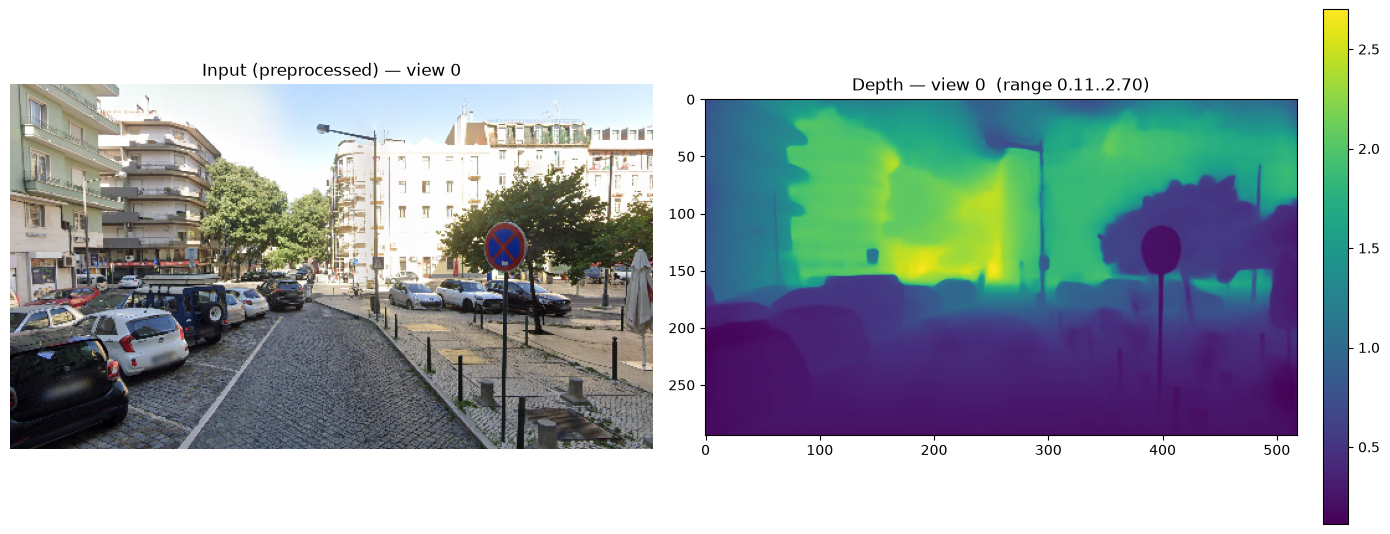

intrinsic[0]=
 tensor([[274.4496,   0.0000, 259.0000],
        [  0.0000, 274.4287, 147.0000],
        [  0.0000,   0.0000,   1.0000]])
extrinsic[0]=
 tensor([[ 1.0000e+00,  3.0637e-04,  7.8971e-04, -3.2020e-04],
        [-3.0661e-04,  1.0000e+00,  3.0773e-04, -8.8477e-06],
        [-7.8962e-04, -3.0797e-04,  1.0000e+00, -3.2481e-03]])


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(images[0].numpy().transpose(1, 2, 0))
axes[0].set_title("Input (preprocessed) — view 0")
axes[0].axis("off")

d0 = depth[0].numpy().squeeze()          # (H, W)
im = axes[1].imshow(d0, cmap="viridis")
axes[1].set_title(f"Depth — view 0  (range {d0.min():.2f}..{d0.max():.2f})")
plt.colorbar(im, ax=axes[1], fraction=0.04, pad=0.04)

plt.tight_layout()
plt.show()

print("intrinsic[0]=\n", intrinsic[0])
print("extrinsic[0]=\n", extrinsic[0])


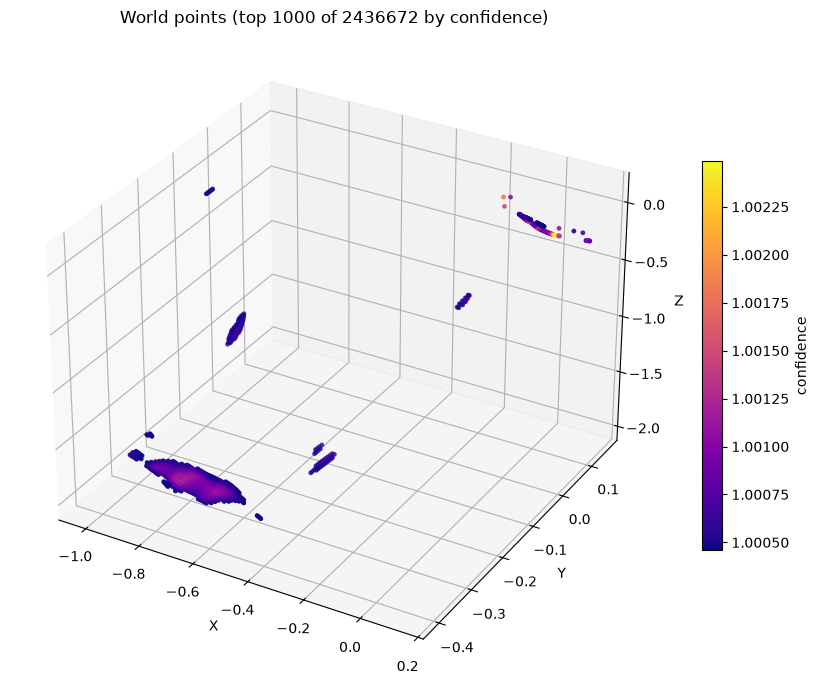

In [9]:
# 3D scatter of the aggregated world point cloud (downsampled for display)
from mpl_toolkits.mplot3d import Axes3D

wp  = world_points.reshape(-1, 3).numpy()      # (S*H*W, 3)
wc  = world_points_c.reshape(-1).numpy()       # (S*H*W,)
n   = min(1000, len(wc))                       # keep top-1000 by confidence
top = np.argpartition(wc, -n)[-n:]
P   = wp[top]

fig = plt.figure(figsize=(9, 7))
ax  = fig.add_subplot(111, projection="3d")
sc  = ax.scatter(P[:, 0], P[:, 1], P[:, 2], s=6, c=wc[top], cmap="plasma")
plt.colorbar(sc, ax=ax, shrink=0.6, label="confidence")
ax.set_xlabel("X"); ax.set_ylabel("Y"); ax.set_zlabel("Z")
ax.set_title(f"World points (top {len(P)} of {len(wp)} by confidence)")
plt.tight_layout()
plt.show()


## 6. Save the reconstruction (tensors) to `test_piv_tensors.npz`


In [8]:
os.makedirs(OUT_DIR, exist_ok=True)
npy_path = os.path.join(OUT_DIR, "test_piv_tensors.npz")

np.savez_compressed(npy_path,
    world_points=world_points.numpy(),
    world_points_conf=world_points_c.numpy(),
    depth=depth.numpy().squeeze(-1),
    depth_conf=depth_conf.numpy(),
    extrinsic=extrinsic.numpy(),
    intrinsic=intrinsic.numpy(),
    images=images.numpy(),
    input_files=np.array([os.path.basename(p) for p in paths]),
)
print("wrote", npy_path, f"({os.path.getsize(npy_path)/1e6:.1f} MB)")


wrote /home/manuelf/VisionIST_Library/boxes/vggt/test/test_piv_out/test_piv_tensors.npz (45.5 MB)


## 7. Export to the images folder (`~/test_piv`)

Writes into `~/test_piv/vggt_output/`:
  * `images_resized/<stem>.png`  — the 350x518 frames the model saw   (viewable RGB)
  * `depthmaps_view/<stem>.png`  — depth, viewable colormap           (display only)
  * `depth/<stem>.npy`           — depth, exact float32, lossless     (np.load-able)
  * `depth/depth_all.npy`        — all views stacked (S,H,W) float32
  * `intrinsics.json`            — per-view intrinsic/extrinsic + mapping

The viewable depth PNG is a colormap (display only) — do not read values from it.
For the real data, load the `.npy` (lossless: reloads to the exact same float32 array):

```python
>>> import numpy as np
>>> d = np.load("~/test_piv/vggt_output/depth/DSC_0326.npy")   # (350, 518) float32
```


In [11]:
import os, json
import numpy as np
from PIL import Image
import matplotlib
import matplotlib.colors as mcolors

EXP      = os.path.expanduser("~/test_piv/praca_1/vggt_output")
img_dir  = os.path.join(EXP, "images_resized")
view_dir = os.path.join(EXP, "depthmaps_view")
npy_dir  = os.path.join(EXP, "depth")
os.makedirs(img_dir, exist_ok=True); os.makedirs(view_dir, exist_ok=True); os.makedirs(npy_dir, exist_ok=True)

# drop the old layout's `depthmaps/` folder if a previous run made it
_old = os.path.join(EXP, "depthmaps")
if os.path.isdir(_old):
    for fn in os.listdir(_old): os.remove(os.path.join(_old, fn))
    os.rmdir(_old)

S    = int(intrinsic.shape[0])            # == len(paths)
cmap = matplotlib.colormaps.get_cmap("viridis")
def depth_view_png(d: np.ndarray) -> np.ndarray:
    lo, hi = float(d.min()), float(d.max())
    if hi - lo < 1e-9: hi = lo + 1.0
    return (cmap(mcolors.Normalize(lo, hi)(d))[..., :3] * 255).astype(np.uint8)

depths = [depth[i].numpy().squeeze() for i in range(S)]   # (H, W) float32 each
meta   = {"source": "vggt box (boxes/vggt)",
          "num_views": S,
          "resized_shape_hw": [int(images.shape[-2]), int(images.shape[-1])],
          "depth_view_png": "viridis colormap, per-view normalized (display only — do not read values)",
          "depth_npy": "float32, lossless, load with np.load; per-view (H,W) or depth/depth_all.npy (S,H,W)",
          "views": []}
made = []
for i in range(S):
    stem = os.path.splitext(os.path.basename(paths[i]))[0]
    d    = depths[i]

    ip   = os.path.join(img_dir, stem + ".png")
    Image.fromarray(np.clip(images[i].numpy().transpose(1, 2, 0) * 255, 0, 255).astype(np.uint8)).save(ip)
    made.append(ip)

    vp   = os.path.join(view_dir, stem + ".png"); Image.fromarray(depth_view_png(d)).save(vp); made.append(vp)

    npy  = os.path.join(npy_dir, stem + ".npy"); np.save(npy, d.astype(np.float32)); made.append(npy)

    meta["views"].append({
        "file": os.path.basename(paths[i]),
        "image_resized": os.path.join("images_resized", stem + ".png"),
        "depth_view":    os.path.join("depthmaps_view", stem + ".png"),
        "depth_npy":     os.path.join("depth", stem + ".npy"),
        "intrinsic": intrinsic[i].numpy().tolist(),
        "extrinsic": extrinsic[i].numpy().tolist(),
        "depth_min": float(d.min()), "depth_max": float(d.max()),
    })
    print(f"  [{i+1}/{S}] {stem:<10} depth {d.min():.3f}..{d.max():.3f}")

allnpy = os.path.join(npy_dir, "depth_all.npy")
np.save(allnpy, np.stack(depths, axis=0).astype(np.float32)); made.append(allnpy)

with open(os.path.join(EXP, "intrinsics.json"), "w") as f:
    json.dump(meta, f, indent=2)

# PROOF the .npy reloads to the exact same array it was saved from (lossless round-trip)
_loaded = np.load(os.path.join(npy_dir, os.path.splitext(os.path.basename(paths[0]))[0] + ".npy"))
ok = np.array_equal(depths[0], _loaded)
assert ok, "depth .npy did NOT round-trip exactly!"
print(f"\nround-trip  np.load(...) == in-memory depth  ->  {ok}"
      f"   ({_loaded.shape} {_loaded.dtype})")
print(f"wrote intrinsics.json; total {len(made) + 1} files under {EXP}")


  [1/16] crop_yaw0  depth 0.113..2.700
  [2/16] crop_yaw1  depth 0.070..2.431
  [3/16] crop_yaw10 depth 0.088..2.327
  [4/16] crop_yaw11 depth 0.100..1.846
  [5/16] crop_yaw12 depth 0.101..1.076
  [6/16] crop_yaw13 depth 0.089..2.209
  [7/16] crop_yaw14 depth 0.116..2.684
  [8/16] crop_yaw15 depth 0.106..2.905
  [9/16] crop_yaw2  depth 0.091..3.107
  [10/16] crop_yaw3  depth 0.116..2.632
  [11/16] crop_yaw4  depth 0.111..2.031
  [12/16] crop_yaw5  depth 0.116..0.756
  [13/16] crop_yaw6  depth 0.172..1.668
  [14/16] crop_yaw7  depth 0.169..2.233
  [15/16] crop_yaw8  depth 0.144..2.292
  [16/16] crop_yaw9  depth 0.111..2.464

round-trip  np.load(...) == in-memory depth  ->  True   ((294, 518) float32)
wrote intrinsics.json; total 50 files under /home/manuelf/test_piv/praca_1/vggt_output
